## 1. Hugging Face Login

#### This imports the token from Kaggle Secrets, so make sure the secret is set correctly before running the code.

In [1]:
# =========================================================
# Phase 1: T5 Encoder-Decoder Legal Model Pretraining
# =========================================================

# --- Cell 1: Install Dependencies ---
# --- Cell 1: Install Dependencies ---
!pip uninstall -y transformers huggingface-hub tokenizers safetensors
!pip install "transformers==4.49.0" "huggingface-hub>=0.23.0"
!pip install ijson


Found existing installation: transformers 5.0.0
Uninstalling transformers-5.0.0:
  Successfully uninstalled transformers-5.0.0
Found existing installation: huggingface_hub 1.11.0
Uninstalling huggingface_hub-1.11.0:
  Successfully uninstalled huggingface_hub-1.11.0
Found existing installation: tokenizers 0.22.2
Uninstalling tokenizers-0.22.2:
  Successfully uninstalled tokenizers-0.22.2
Found existing installation: safetensors 0.7.0
Uninstalling safetensors-0.7.0:
  Successfully uninstalled safetensors-0.7.0
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 78.6 MB/s eta 0:00:00:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 29.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 516.0/516.0 kB 26.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 89.9 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 149.8/149.8 kB 3.4 MB/s eta 

In [2]:

# --- Cell 2: Imports ---
import os
import json
import random
import time
import math
import zipfile
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import ijson
from huggingface_hub import login, hf_hub_download
from tokenizers import ByteLevelBPETokenizer
from transformers import (
    PreTrainedTokenizerFast,
    T5Config,
    T5ForConditionalGeneration,
    DataCollatorForSeq2Seq,
    TrainingArguments,
    Trainer
)
from transformers.trainer_utils import get_last_checkpoint
from datasets import Dataset

## 2. Check GPU

In [3]:
# --- Cell 4: Check GPU ---
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CUDA available: True
GPU count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4


## 3. Configuration

#### this is sample configuration, you are free to modify any parameter to train the best performing model

In [ ]:
# --- Cell 3: Configuration & Authentication ---
login(token=os.environ["HF_TOKEN"])

HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
OUTPUT_DIR = "./cs781_phase1_encdec"
TOKENIZER_DIR = os.path.join(OUTPUT_DIR, "custom_legal_tokenizer")
MODEL_OUTPUT_DIR = os.path.join(OUTPUT_DIR, "legal-t5-baseline")
PREDICTION_PATH = os.path.join(OUTPUT_DIR, "prediction.json")
SUBMISSION_ZIP = os.path.join(OUTPUT_DIR, "submission.zip")
LOSS_PLOT_PATH = os.path.join(OUTPUT_DIR, "training_validation_loss.png")

for path in [OUTPUT_DIR, TOKENIZER_DIR, MODEL_OUTPUT_DIR]:
    os.makedirs(path, exist_ok=True)

# Budgets & Architecture (T5-Base Scale ~110M Params)
TRAIN_TOKENS = 200_000_000
VAL_TOKENS = 5_000_000
MAX_SOURCE_LENGTH = 1024
MAX_TARGET_LENGTH = 256

D_MODEL = 768
NUM_LAYERS = 6          # 6 encoder layers, 6 decoder layers
NUM_HEADS = 12
VOCAB_SIZE = 32000

# Decoding Parameters
TARGET_GENERATION_WORDS = 128
MAX_GENERATION_TOKENS = 384
TEMPERATURE = 0.1
TOP_P = 0.95

In [5]:
# from transformers import AutoTokenizer, T5ForConditionalGeneration
# import torch

# # Replace with your actual Hugging Face model repository ID
# HF_MODEL_REPO = "A-240242/legal-encdec-checkpoints" 

# print("Fetching tokenizer and trained model from Hugging Face Hub...")
# tokenizer = AutoTokenizer.from_pretrained(HF_MODEL_REPO)
# model = T5ForConditionalGeneration.from_pretrained(HF_MODEL_REPO)

# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# model.to(device)
# model.eval()

# print("Model and tokenizer successfully fetched from Hub and ready!")

## 4. Load Tokenizer

In [5]:
# --- Cell 5: Load Tokenizer Corpus & Train Tokenizer ---
sources = {
    "supreme_court": {"file": "Phase_1_Pretraining/Train/train_supreme_court.json", "ratio": 0.45},
    "high_courts": {"file": "Phase_1_Pretraining/Train/train_high_courts.json", "ratio": 0.35},
    "acts": {"file": "Phase_1_Pretraining/Train/train_acts.json", "ratio": 0.15},
    "tribunals": {"file": "Phase_1_Pretraining/Train/train_tribunals.json", "ratio": 0.05}
}

file_paths = {}
for name, config_source in sources.items():
    file_paths[name] = hf_hub_download(repo_id=HF_DATASET_REPO, filename=config_source["file"], repo_type="dataset", token=HF_TOKEN)

def get_tokenizer_corpus(paths, max_docs=1000): 
    for name, path in paths.items():
        print(f"Sampling {max_docs} documents from {name} for tokenizer...")
        count = 0
        with open(path, "rb") as f:
            for record in ijson.items(f, "item"):
                if "text" in record:
                    yield record["text"]
                    count += 1
                if count >= max_docs:
                    break

print("Training custom Byte-Level BPE tokenizer from scratch...")
raw_tokenizer = ByteLevelBPETokenizer()

raw_tokenizer.train_from_iterator(
    get_tokenizer_corpus(file_paths, max_docs=1000),
    vocab_size=VOCAB_SIZE,
    min_frequency=2,
    special_tokens=["<|endoftext|>"]
)

tokenizer = PreTrainedTokenizerFast(
    tokenizer_object=raw_tokenizer._tokenizer,
    bos_token="<|endoftext|>",
    eos_token="<|endoftext|>",
    pad_token="<|endoftext|>"
)
tokenizer.padding_side = "right"  # Standard for T5 Encoder-Decoder
tokenizer.save_pretrained(TOKENIZER_DIR)
print(f"Custom tokenizer saved to {TOKENIZER_DIR}")

Phase_1_Pretraining/Train/train_supreme_(…):   0%|          | 0.00/1.32G [00:00<?, ?B/s]

Phase_1_Pretraining/Train/train_high_cou(…):   0%|          | 0.00/10.7G [00:00<?, ?B/s]

Phase_1_Pretraining/Train/train_acts.jso(…):   0%|          | 0.00/729M [00:00<?, ?B/s]

Phase_1_Pretraining/Train/train_tribunal(…):   0%|          | 0.00/6.48G [00:00<?, ?B/s]

Training custom Byte-Level BPE tokenizer from scratch...
Sampling 1000 documents from supreme_court for tokenizer...
Sampling 1000 documents from high_courts for tokenizer...
Sampling 1000 documents from acts for tokenizer...
Sampling 1000 documents from tribunals for tokenizer...



Custom tokenizer saved to ./cs781_phase1_encdec/custom_legal_tokenizer


## 5. Download Training Data From Hugging Face

In [6]:
# --- Cell 6: Stratified Seq2Seq Dataset Generation (OOM-Safe Token Collection) ---
train_sources_data, val_sources_data = [], []
random.seed(42)

for source, config_source in sources.items():
    target_train_tokens = int(TRAIN_TOKENS * config_source["ratio"])
    target_val_tokens = int(VAL_TOKENS * config_source["ratio"])
    
    print(f"Processing Seq2Seq pairs for {source}...")
    source_train_tokens, source_val_tokens = [], []
    
    with open(file_paths[source], "rb") as f:
        for record in ijson.items(f, "item"):
            if "text" not in record:
                continue
            
            tokens = tokenizer.encode(record["text"])
            if len(tokens) < 50:
                continue
                
            if random.random() < 0.05:
                if len(source_val_tokens) < target_val_tokens:
                    source_val_tokens.extend(tokens[:target_val_tokens - len(source_val_tokens)])
            else:
                if len(source_train_tokens) < target_train_tokens:
                    source_train_tokens.extend(tokens[:target_train_tokens - len(source_train_tokens)])
                    
            if len(source_train_tokens) >= target_train_tokens and len(source_val_tokens) >= target_val_tokens:
                break
                
    train_sources_data.extend(source_train_tokens)
    val_sources_data.extend(source_val_tokens)
    print(f"Finished {source}: {len(source_train_tokens)} train tokens, {len(source_val_tokens)} val tokens.")

Processing Seq2Seq pairs for supreme_court...
Finished supreme_court: 90000000 train tokens, 2250000 val tokens.
Processing Seq2Seq pairs for high_courts...
Finished high_courts: 70000000 train tokens, 1750000 val tokens.
Processing Seq2Seq pairs for acts...
Finished acts: 30000000 train tokens, 750000 val tokens.
Processing Seq2Seq pairs for tribunals...
Finished tribunals: 10000000 train tokens, 250000 val tokens.


## 6. Create Train and Validation Tokens Set

## 7. Create Token Blocks

In [7]:
# --- Cell 7: Create Seq2Seq Token Chunks ---
def create_seq2seq_pairs_from_tokens(token_list, max_source_len, max_target_len):
    chunk_size = max_source_len + max_target_len
    total_length = (len(token_list) // chunk_size) * chunk_size
    
    input_ids, labels = [], []
    for i in range(0, total_length, chunk_size):
        chunk = token_list[i:i + chunk_size]
        src = chunk[:max_source_len]
        tgt = chunk[max_source_len:max_source_len + max_target_len]
        input_ids.append(src)
        labels.append(tgt)
    return input_ids, labels

train_src, train_lbl = create_seq2seq_pairs_from_tokens(train_sources_data, MAX_SOURCE_LENGTH, MAX_TARGET_LENGTH)
val_src, val_lbl = create_seq2seq_pairs_from_tokens(val_sources_data, MAX_SOURCE_LENGTH, MAX_TARGET_LENGTH)

## 8. Create Datasets

In [8]:
# --- Cell 8: Create Datasets ---
train_dataset = Dataset.from_dict({
    "input_ids": train_src,
    "attention_mask": [[1] * len(x) for x in train_src],
    "labels": train_lbl
})
val_dataset = Dataset.from_dict({
    "input_ids": val_src,
    "attention_mask": [[1] * len(x) for x in val_src],
    "labels": val_lbl
})

print(train_dataset)
print(val_dataset)

Dataset({
    features: ['input_ids', 'attention_mask', 'labels'],
    num_rows: 156250
})
Dataset({
    features: ['input_ids', 'attention_mask', 'labels'],
    num_rows: 3906
})


## 9. Define The Model

In [9]:
from transformers import PretrainedConfig, GenerationMixin
from transformers.modeling_outputs import Seq2SeqLMOutput


# Define a proper Hugging Face configuration class for your custom model
class CustomLegalConfig(PretrainedConfig):
  model_type = "custom_legal_encdec"

  def __init__(
      self,
      vocab_size=32000,
      d_model=768,
      pad_token_id=0,
      eos_token_id=0,
      **kwargs,
  ):
    super().__init__(
        pad_token_id=pad_token_id, eos_token_id=eos_token_id, **kwargs
    )
    self.vocab_size = vocab_size
    self.d_model = d_model
    self.decoder_start_token_id = pad_token_id
    self.is_encoder_decoder = True
    self.tie_word_embeddings = False

In [10]:
# --- Cell 9: Define Custom Encoder-Decoder Model with Generation Support ---
import math
import torch
import torch.nn as nn
from transformers import GenerationMixin
from transformers.modeling_outputs import Seq2SeqLMOutput

class CustomLegalEncoderDecoder(nn.Module, GenerationMixin):
    def __init__(
        self, 
        vocab_size=32000, 
        d_model=768, 
        num_layers=6, 
        num_heads=12, 
        d_ff=2048, 
        max_seq_len=1024,
        dropout=0.1,
        pad_token_id=0,
        eos_token_id=0
    ):
        super().__init__()
        self.d_model = d_model
        
        # Required configuration attributes for Hugging Face GenerationMixin
        self.config = CustomLegalConfig(
            vocab_size=vocab_size,
            d_model=d_model,
            pad_token_id=pad_token_id,
            eos_token_id=eos_token_id,
        )
        
        self.main_input_name = "input_ids"
        self.embedding = nn.Embedding(vocab_size, d_model, padding_idx=pad_token_id)
        self.pos_embedding = nn.Embedding(max_seq_len, d_model)
        
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=num_heads, dim_feedforward=d_ff, dropout=dropout, batch_first=True
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        
        decoder_layer = nn.TransformerDecoderLayer(
            d_model=d_model, nhead=num_heads, dim_feedforward=d_ff, dropout=dropout, batch_first=True
        )
        self.decoder = nn.TransformerDecoder(decoder_layer, num_layers=num_layers)
        
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)
        self.lm_head.weight = self.embedding.weight

    def get_encoder(self):
        return self.encoder
    
    def can_generate(self):
      return True

    def _get_pos_ids(self, x):
        seq_len = x.size(1)
        return torch.arange(seq_len, device=x.device).unsqueeze(0).expand(x.size(0), -1)
    @property
    def device(self):
        return next(self.parameters()).device
    def forward(
        self, 
        input_ids=None, 
        attention_mask=None, 
        decoder_input_ids=None, 
        decoder_attention_mask=None, 
        labels=None, 
        encoder_outputs=None,
        past_key_values=None,
        use_cache=False,
        **kwargs
    ):
        # 1. Handle Encoder pass if encoder_outputs are not cached yet during generation
        if encoder_outputs is None:
            src_pos = self._get_pos_ids(input_ids)
            src_emb = self.embedding(input_ids) * math.sqrt(self.d_model) + self.pos_embedding(src_pos)
            src_key_padding_mask = (attention_mask == 0) if attention_mask is not None else None
            memory = self.encoder(src_emb, src_key_padding_mask=src_key_padding_mask)
        else:
            memory = encoder_outputs[0]
            src_key_padding_mask = (kwargs.get("attention_mask", None) == 0) if "attention_mask" in kwargs else None

        # 2. Handle Training vs. Generation decoder inputs
        if decoder_input_ids is None and labels is not None:
            decoder_input_ids = self._shift_right(labels)
        elif decoder_input_ids is None:
            # Fallback initialization for generation start
            decoder_input_ids = torch.full(
                (memory.size(0), 1), self.config.pad_token_id, dtype=torch.long, device=memory.device
            )

        # 3. Decode Target Pass
        tgt_pos = self._get_pos_ids(decoder_input_ids)
        tgt_emb = self.embedding(decoder_input_ids) * math.sqrt(self.d_model) + self.pos_embedding(tgt_pos)
        
        tgt_seq_len = decoder_input_ids.size(1)
        tgt_mask = nn.Transformer.generate_square_subsequent_mask(tgt_seq_len, device=decoder_input_ids.device)
        tgt_key_padding_mask = (decoder_attention_mask == 0) if decoder_attention_mask is not None else None
        
        decoder_output = self.decoder(
            tgt=tgt_emb,
            memory=memory,
            tgt_mask=tgt_mask,
            tgt_key_padding_mask=tgt_key_padding_mask,
            memory_key_padding_mask=src_key_padding_mask
        )
        
        logits = self.lm_head(decoder_output)
        
        loss = None
        if labels is not None:
            loss_fn = nn.CrossEntropyLoss(ignore_index=-100)
            loss = loss_fn(logits.view(-1, logits.size(-1)), labels.view(-1))
            
        return Seq2SeqLMOutput(
            loss=loss, 
            logits=logits, 
            encoder_last_hidden_state=memory
        )

    def prepare_inputs_for_generation(
        self, 
        decoder_input_ids, 
        past_key_values=None, 
        attention_mask=None, 
        encoder_outputs=None, 
        **kwargs
    ):
        return {
            "decoder_input_ids": decoder_input_ids,
            "encoder_outputs": encoder_outputs,
            "attention_mask": attention_mask,
            "decoder_attention_mask": kwargs.get("decoder_attention_mask", None)
        }

    def _shift_right(self, input_ids):
        decoder_start_token_id = self.config.pad_token_id
        shifted = input_ids.new_zeros(input_ids.shape)
        shifted[:, 1:] = input_ids[:, :-1].clone()
        shifted[:, 0] = decoder_start_token_id
        return shifted

# Initialize your custom-built encoder-decoder from scratch
model = CustomLegalEncoderDecoder(
    vocab_size=len(tokenizer),
    d_model=D_MODEL,
    num_layers=NUM_LAYERS,
    num_heads=NUM_HEADS,
    pad_token_id=tokenizer.pad_token_id,
    eos_token_id=tokenizer.eos_token_id
)

model_size = sum(p.numel() for p in model.parameters())
print(f"Custom Built Encoder-Decoder Model size: {model_size / 1e6:.2f}M parameters")

Custom Built Encoder-Decoder Model size: 105.71M parameters


In [13]:
import torch
from huggingface_hub import hf_hub_download
from safetensors.torch import load_file
from transformers import AutoTokenizer

HF_MODEL_REPO = "A-240242/legal-encdec-checkpoints"

print("Fetching tokenizer and trained model weights from Hugging Face Hub...")
# tokenizer = AutoTokenizer.from_pretrained(HF_MODEL_REPO)

# 1. Re-initialize your custom model architecture
model = CustomLegalEncoderDecoder(
    vocab_size=len(tokenizer),
    d_model=768,  
    num_layers=6,  
    num_heads=12,  
    pad_token_id=tokenizer.pad_token_id,
    eos_token_id=tokenizer.eos_token_id,
)

# 2. Download and load the saved safetensors weights from your Hub repo
model_weight_path = hf_hub_download(
    repo_id=HF_MODEL_REPO, 
    filename="model.safetensors"
)
model.load_state_dict(load_file(model_weight_path))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
model.eval()

print("Custom model and tokenizer successfully fetched from Hub and ready!")

Fetching tokenizer and trained model weights from Hugging Face Hub...


model.safetensors:   0%|          | 0.00/521M [00:00<?, ?B/s]

Custom model and tokenizer successfully fetched from Hub and ready!


In [14]:
TOKENIZER_DIR = "./cs781_phase1_encdec/custom_legal_tokenizer"
print("Loading local tokenizer...")
tokenizer = PreTrainedTokenizerFast.from_pretrained(TOKENIZER_DIR)

Loading local tokenizer...


## 10. Training Arguments

In [12]:
# --- Cell 10: Training Arguments ---
training_args = TrainingArguments(
    output_dir=MODEL_OUTPUT_DIR,
    report_to="none",
    num_train_epochs=1,
    per_device_train_batch_size=2,
    per_device_eval_batch_size=2,
    gradient_accumulation_steps=4,
    learning_rate=3e-4,
    weight_decay=0.1,
    warmup_steps=500,
    lr_scheduler_type="cosine",
    fp16=torch.cuda.is_available(),
    eval_strategy="steps",
    eval_steps=1000,
    save_strategy="steps",
    save_steps=1000,
    push_to_hub=True,
    hub_model_id="A-240242/legal-encdec-checkpoints",
    hub_strategy="checkpoint",
    hub_token=HF_TOKEN,
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    logging_steps=100,
    seed=42
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    data_collator=DataCollatorForSeq2Seq(tokenizer=tokenizer, model=model),
)


## 11. Training

In [13]:
# --- Cell 11: Training ---
EPOCHS = training_args.num_train_epochs
start_time = time.time()

MOUNTED_CHECKPOINT_DIR = "/kaggle/input/legal-encdec-checkpoints"
latest_checkpoint = (
    get_last_checkpoint(MOUNTED_CHECKPOINT_DIR)
    if os.path.exists(MOUNTED_CHECKPOINT_DIR)
    else None
)

if latest_checkpoint is not None:
  print(f"Auto-detected previous run. Resuming directly from: {latest_checkpoint}")
else:
  print("No prior checkpoint found. Starting training from scratch.")

# Break the memory sharing between embedding and lm_head for your custom model
if hasattr(model, "lm_head") and hasattr(model, "embedding"):
  if model.lm_head.weight.data_ptr() == model.embedding.weight.data_ptr():
    model.lm_head.weight = nn.Parameter(model.lm_head.weight.clone())
    print("Successfully un-tied custom model weights for safetensors.")

trainer.train(resume_from_checkpoint=latest_checkpoint)

training_time = time.time() - start_time
tokens_per_epoch = len(train_dataset) * (MAX_SOURCE_LENGTH + MAX_TARGET_LENGTH)
total_tokens = tokens_per_epoch * EPOCHS
tokens_per_second = total_tokens / training_time

print(f"Training time: {training_time / 3600:.2f} hours")
print(f"Training speed: {tokens_per_second:,.0f} tokens/sec")

No prior checkpoint found. Starting training from scratch.
Successfully un-tied custom model weights for safetensors.


/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Step,Training Loss,Validation Loss
1000,38.014400,7.651548
2000,24.101500,5.495131
3000,18.853600,4.694366
4000,17.531600,4.319854
5000,16.347000,4.208736
6000,15.878000,4.085261
7000,15.219400,4.010241
8000,14.929200,3.948772
9000,15.085800,3.935153


/usr/local/lib/python3.12/dist-packages/torch/nn/modules/transformer.py:531: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(
/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type

Training time: 6.35 hours
Training speed: 8,743 tokens/sec


## 12. Perplexity

In [14]:
# --- Cell 12: Perplexity ---
eval_results = trainer.evaluate()
eval_loss = eval_results["eval_loss"]
perplexity = math.exp(eval_loss)
print(f"Final Validation Loss: {eval_loss:.6f}")
print(f"Final Validation Perplexity: {perplexity:.4f}")

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Final Validation Loss: 3.935153
Final Validation Perplexity: 51.1700


## 13. Plot Training and Validation Loss

Loss plot saved to: ./cs781_phase1_encdec/training_validation_loss.png


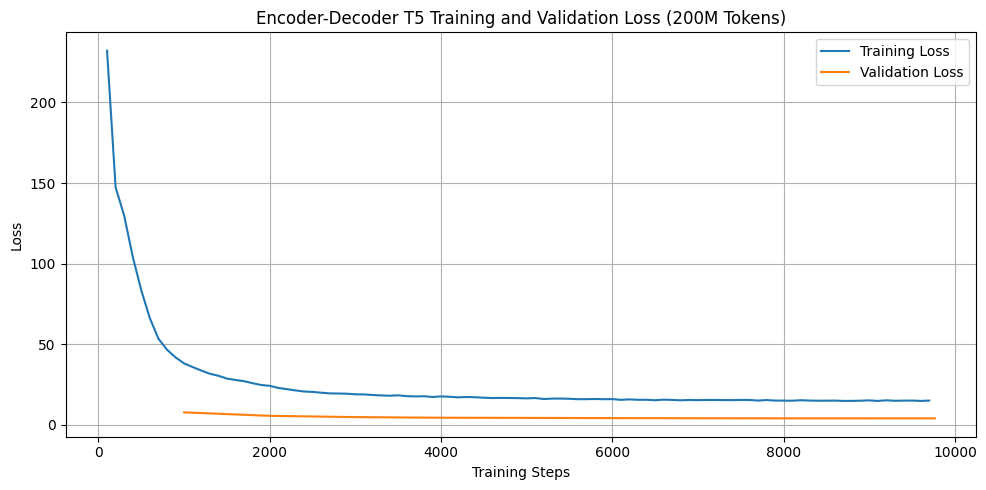

In [15]:
# --- Cell 13: Plot Training and Validation Loss ---
logs = trainer.state.log_history
train_steps, train_loss = [], []
eval_steps, eval_loss_history = [], []

for log in logs:
    if "loss" in log and "step" in log:
        train_steps.append(log["step"])
        train_loss.append(log["loss"])
    if "eval_loss" in log and "step" in log:
        eval_steps.append(log["step"])
        eval_loss_history.append(log["eval_loss"])

plt.figure(figsize=(10, 5))
plt.plot(train_steps, train_loss, label="Training Loss")
plt.plot(eval_steps, eval_loss_history, label="Validation Loss")
plt.xlabel("Training Steps")
plt.ylabel("Loss")
plt.title("Encoder-Decoder T5 Training and Validation Loss (200M Tokens)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(LOSS_PLOT_PATH, dpi=200)
print(f"Loss plot saved to: {LOSS_PLOT_PATH}")



## 14. Save Final Model to Kaggle Output

In [16]:
# --- Cell 14: Save Final Model to Kaggle Output ---
trainer.save_model(MODEL_OUTPUT_DIR)
tokenizer.save_pretrained(MODEL_OUTPUT_DIR)
print(f"Final model saved to {MODEL_OUTPUT_DIR}")

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

Final model saved to ./cs781_phase1_encdec/legal-t5-baseline


## 15. Push Model to Hugging Face Hub

In [17]:
# model.push_to_hub(HF_MODEL_REPO, token=HF_TOKEN)
# tokenizer.push_to_hub(HF_MODEL_REPO, token=HF_TOKEN)

# print("Model and tokenizer pushed successfully.")

## 16. Load Test Data from HuggingFace

In [22]:
import torch
import torch.nn.functional as F

def generate(
    self, 
    input_ids, 
    attention_mask=None, 
    max_new_tokens=384, 
    temperature=0.7, 
    top_p=0.9, 
    repetition_penalty=1.3,
    eos_token_id=None,
    pad_token_id=None
):
    self.eval()
    device = input_ids.device
    batch_size = input_ids.size(0)
    
    pad_id = pad_token_id if pad_token_id is not None else self.config.pad_token_id
    eos_id = eos_token_id if eos_token_id is not None else self.config.eos_token_id

    # 1. Encode prompt once
    src_pos = self._get_pos_ids(input_ids)
    src_emb = self.embedding(input_ids) * math.sqrt(self.d_model) + self.pos_embedding(src_pos)
    src_key_padding_mask = (attention_mask == 0) if attention_mask is not None else None
    memory = self.encoder(src_emb, src_key_padding_mask=src_key_padding_mask)

    # 2. Start decoding with decoder_start_token
    curr_decoder_input_ids = torch.full((batch_size, 1), pad_id, dtype=torch.long, device=device)
    unfinished_sequences = torch.ones(batch_size, dtype=torch.long, device=device)

    for _ in range(max_new_tokens):
        tgt_pos = self._get_pos_ids(curr_decoder_input_ids)
        tgt_emb = self.embedding(curr_decoder_input_ids) * math.sqrt(self.d_model) + self.pos_embedding(tgt_pos)
        
        tgt_seq_len = curr_decoder_input_ids.size(1)
        tgt_mask = nn.Transformer.generate_square_subsequent_mask(tgt_seq_len, device=device)
        
        decoder_output = self.decoder(
            tgt=tgt_emb,
            memory=memory,
            tgt_mask=tgt_mask,
            memory_key_padding_mask=src_key_padding_mask
        )
        
        # Logits for the next token only
        next_token_logits = self.lm_head(decoder_output[:, -1, :])

        # Apply repetition penalty
        if repetition_penalty != 1.0:
            for b in range(batch_size):
                prev_tokens = curr_decoder_input_ids[b].unique()
                for token in prev_tokens:
                    if next_token_logits[b, token] > 0:
                        next_token_logits[b, token] /= repetition_penalty
                    else:
                        next_token_logits[b, token] *= repetition_penalty

        # Temperature scaling & top-p sampling
        if temperature > 0:
            next_token_logits = next_token_logits / temperature
            if top_p < 1.0:
                sorted_logits, sorted_indices = torch.sort(next_token_logits, descending=True)
                cumulative_probs = torch.cumsum(F.softmax(sorted_logits, dim=-1), dim=-1)
                
                # Remove tokens with cumulative probability above top_p threshold
                sorted_indices_to_remove = cumulative_probs > top_p
                sorted_indices_to_remove[..., 1:] = sorted_indices_to_remove[..., :-1].clone()
                sorted_indices_to_remove[..., 0] = 0
                
                indices_to_remove = sorted_indices_to_remove.scatter(1, sorted_indices, sorted_indices_to_remove)
                next_token_logits[indices_to_remove] = -float("Inf")
                
            probs = F.softmax(next_token_logits, dim=-1)
            next_tokens = torch.multinomial(probs, num_samples=1)
        else:
            next_tokens = torch.argmax(next_token_logits, dim=-1, keepdim=True)

        # Retain pad token for finished sequences
        next_tokens = next_tokens * unfinished_sequences.unsqueeze(1) + pad_id * (1 - unfinished_sequences).unsqueeze(1)
        curr_decoder_input_ids = torch.cat([curr_decoder_input_ids, next_tokens], dim=-1)

        # Check for EOS
        if eos_id is not None:
            unfinished_sequences = unfinished_sequences & (next_tokens.squeeze(-1) != eos_id).long()
            if unfinished_sequences.max() == 0:
                break

    return curr_decoder_input_ids

# Attach directly to the existing model object
CustomLegalEncoderDecoder.generate = generate

In [ ]:
# --- Cell 16: Load Test Data and Generate Predictions ---
import json
import torch
from huggingface_hub import hf_hub_download
from transformers import GenerationConfig
from tqdm.auto import tqdm

test_file_path = hf_hub_download(repo_id=HF_DATASET_REPO, filename="Phase_1_Pretraining/Test/test.json", repo_type="dataset", token=HF_TOKEN)

with open(test_file_path, "r", encoding="utf-8") as f:
    test_data = json.load(f)

# --- Attach required Hugging Face metadata ---
model.generation_config = GenerationConfig(
    pad_token_id=tokenizer.pad_token_id,
    eos_token_id=tokenizer.eos_token_id,
    decoder_start_token_id=tokenizer.pad_token_id,
    is_encoder_decoder=True,
)
model.base_model_prefix = "custom_model"

# THE FINAL FIX: Add the input name flags to bypass the TransformerEncoder attribute error
model.main_input_name = "input_ids"
model.encoder.main_input_name = "input_ids"

model.eval()
model.to(device)

predictions = {}
items = list(test_data.items())

for start in tqdm(range(0, len(items), 32), desc="Generating Predictions"):
    batch = items[start:start + 32]
    batch_ids = [str(eid) for eid, _ in batch]
    batch_prompts = [record["text"] for _, record in batch]

    inputs = tokenizer(batch_prompts, return_tensors="pt", padding=True, truncation=True, max_length=MAX_SOURCE_LENGTH)
    
    # Filter out 'token_type_ids' when moving inputs to the GPU
    inputs = {k: v.to(device) for k, v in inputs.items() if k != "token_type_ids"}

    with torch.inference_mode():
        # Cleaned up generate call for the custom method
        outputs = model.generate(
            input_ids=inputs["input_ids"],
            attention_mask=inputs.get("attention_mask", None),
            max_new_tokens=384,
            temperature=0.7,
            top_p=0.9,
            repetition_penalty=1.3,
            eos_token_id=tokenizer.eos_token_id,
            pad_token_id=tokenizer.pad_token_id
        )

    for i, example_id in enumerate(batch_ids):
        generated_text = tokenizer.decode(outputs[i], skip_special_tokens=True)
        generated_words = generated_text.split()[:TARGET_GENERATION_WORDS]
        predictions[example_id] = {"text": " ".join(generated_words)}

Generating Predictions:   0%|          | 0/32 [00:00<?, ?it/s]

## 17. Load Test Prompts

## 18. Load Final Model for Generation

## 19. Generate 128 Words
#### (words, not tokens)

## 20. Generate Predictions for the Test Set

## 21. Save prediction.json

In [ ]:
# --- Cell 21 & 22: Save prediction.json & Create Submission ZIP ---
with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
    json.dump(predictions, f, ensure_ascii=False, indent=2)

print("prediction.json saved successfully:")
print(PREDICTION_PATH)

with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zipf:
    zipf.write(PREDICTION_PATH, arcname="prediction.json")
    
print("CodaBench submission created successfully:")
print(SUBMISSION_ZIP)

## 22. Create CodaBench Submission ZIP